# Crimes of India: Regional Analysis, 2014–2016

This notebook examines recorded Indian Penal Code (IPC) crimes across India’s States and Union Territories using the project’s supplied table. It considers recorded counts, population-adjusted rates, regional changes, and differences between State and UT rate distributions.

> **Scope and interpretation:** Recorded crimes reflect incidents in the reporting system; they are not necessarily the true incidence of all crimes committed. Counts and rates answer different questions and are affected by reporting practices and population differences.

### Research questions

- How did recorded IPC crime totals change from 2014 to 2016?
- Which regions had the highest counts and highest or lowest rates in 2016?
- Which regions experienced the largest count increases and decreases?
- How do crime-rate distributions compare across States and UTs?
- Is projected population linearly associated with crime rate across the 36 regions?

**Source:** `data/raw/Table_1A.1_2016.csv`  
**Period:** 2014–2016  
**Unit of analysis:** 29 States and 7 Union Territories.

## 2. Load and validate the data

The source table includes three aggregate rows—Total States, Total UTs, and Total All-India—in addition to individual regions. We exclude those summary rows before calculating regional results, which avoids counting the same crimes once in regional records and again in aggregate rows. The notebook reads the raw data and independently checks its cleaned records.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

plt.rcParams.update({"font.size": 10, "axes.titlesize": 13})
RAW_RELATIVE_PATH = Path("data") / "raw" / "Table_1A.1_2016.csv"

def find_project_root(start=None):
    """Find the project from the current folder or its parents."""
    current = Path(start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / RAW_RELATIVE_PATH).is_file():
            return candidate
    raise FileNotFoundError(
        f"Could not find {RAW_RELATIVE_PATH}; open Jupyter from the project or notebooks folder."
    )

PROJECT_DIR = find_project_root()
print(f"Notebook kernel interpreter: {sys.executable}")
assert Path(sys.prefix).resolve() == (PROJECT_DIR / ".venv").resolve(), "Select this project’s .venv kernel before running the notebook."
DATA_PATH = PROJECT_DIR / RAW_RELATIVE_PATH
raw_df = pd.read_csv(DATA_PATH)
print(f"Project folder: {PROJECT_DIR}\nRaw file: {DATA_PATH}\nRaw shape: {raw_df.shape}")
display(pd.DataFrame({"column": raw_df.columns, "dtype": raw_df.dtypes.astype(str).values}))
display(raw_df.head())

Notebook kernel interpreter: C:\Users\Subham Mohanty\OneDrive\Documents\crimes of India\.venv\Scripts\python.exe
Project folder: C:\Users\Subham Mohanty\OneDrive\Documents\crimes of India
Raw file: C:\Users\Subham Mohanty\OneDrive\Documents\crimes of India\data\raw\Table_1A.1_2016.csv
Raw shape: (39, 11)


,column,dtype
0,S. No. (Col.1),str
1,Category (Col.2),str
2,State/UT (Col.3),str
3,Year - 2014 (Col.4),int64
4,Year - 2015 (Col.5),int64
5,Year - 2016 (Col.6),int64
6,Percentage Share of State/UT (2016) (Col.7),float64
7,Rank Based on Incidence/ Percentage share (201...,float64
8,Mid-Year Projected Population (In Lakhs) (2016...,float64
9,Rate of Cognizable Crimes (IPC) (2016)++ (Col.10),float64


,S. No. (Col.1),Category (Col.2),State/UT (Col.3),Year - 2014 (Col.4),Year - 2015 (Col.5),Year - 2016 (Col.6),Percentage Share of State/UT (2016) (Col.7),Rank Based on Incidence/ Percentage share (2016) (Col.8),Mid-Year Projected Population (In Lakhs) (2016)+ (Col.9),Rate of Cognizable Crimes (IPC) (2016)++ (Col.10),Rank Based on Crime Rate (2016) (Col.11)
0,1,State,Andhra Pradesh,114604,110693,106774,3.6,13.0,517.4,206.4,15.0
1,2,State,Arunachal Pradesh,2843,2968,2534,0.1,29.0,13.2,192.3,17.0
2,3,State,Assam,94337,103616,102250,3.4,14.0,325.8,313.9,5.0
3,4,State,Bihar,177595,176973,164163,5.5,9.0,1043.0,157.4,22.0
4,5,State,Chhattisgarh,58200,56692,55029,1.8,17.0,259.9,211.7,14.0


In [2]:
EXPECTED_COLUMNS = [
    "serial_no", "category", "state_ut", "crimes_2014", "crimes_2015",
    "crimes_2016", "percentage_share_2016", "incidence_rank_2016",
    "population_lakhs_2016", "crime_rate_2016", "crime_rate_rank_2016",
]
assert raw_df.shape[1] == len(EXPECTED_COLUMNS), f"Expected 11 columns, found {raw_df.shape[1]}"

serial_values = pd.to_numeric(raw_df.iloc[:, 0], errors="coerce")
excluded_rows = raw_df.loc[serial_values.isna()]
expected_summary_names = {"Total (States)", "Total (UTs)", "Total (All-India)"}
excluded_names = set(excluded_rows.iloc[:, 2].astype(str).str.strip())
assert excluded_names == expected_summary_names, f"Unexpected excluded rows: {excluded_names}"

crime = raw_df.loc[serial_values.notna()].copy()
crime.columns = EXPECTED_COLUMNS
crime["serial_no"] = pd.to_numeric(crime["serial_no"], errors="raise").astype(int)
crime["category"] = crime["category"].astype(str).str.strip()
crime["state_ut"] = crime["state_ut"].astype(str).str.strip()
for column in EXPECTED_COLUMNS[3:]:
    crime[column] = pd.to_numeric(crime[column], errors="coerce")

missing = crime.isna().sum()
quality = pd.Series({
    "region records": len(crime),
    "duplicate serial numbers": int(crime["serial_no"].duplicated().sum()),
    "duplicate region names": int(crime["state_ut"].duplicated().sum()),
    "invalid categories": int((~crime["category"].isin(["State", "UT"])).sum()),
    "negative count/population/rate values": int((crime[["crimes_2014", "crimes_2015", "crimes_2016", "population_lakhs_2016", "crime_rate_2016"]] < 0).sum().sum()),
    "missing values": int(missing.sum()),
})
display(quality.to_frame("value"))
display(missing.rename("missing values").to_frame())
assert len(crime) == 36
assert missing.sum() == 0
assert crime["serial_no"].is_unique and crime["state_ut"].is_unique
assert set(crime["category"]) == {"State", "UT"}
assert (crime[["crimes_2014", "crimes_2015", "crimes_2016", "population_lakhs_2016", "crime_rate_2016"]] >= 0).all().all()
print(f"Validation passed: {len(crime)} regions, {(crime.category == 'State').sum()} States, {(crime.category == 'UT').sum()} UTs. Excluded the three aggregate rows.")

# Compare the generated cleaned file, if present, with the raw-source analysis.
processed_path = PROJECT_DIR / "processed" / "cleaned_crime_data.csv"
if processed_path.is_file():
    processed = pd.read_csv(processed_path)
    assert len(processed) == len(crime)
    assert processed["state_ut"].tolist() == crime["state_ut"].tolist()
    for year in (2014, 2015, 2016):
        column = f"crimes_{year}"
        assert np.array_equal(processed[column].to_numpy(), crime[column].to_numpy())
    print("Processed CSV check passed: regional records and annual counts match the raw source.")
else:
    print("No processed CSV was found; the notebook continues from the raw source.")

,value
region records,36
duplicate serial numbers,0
duplicate region names,0
invalid categories,0
negative count/population/rate values,0
missing values,0


,missing values
serial_no,0
category,0
state_ut,0
crimes_2014,0
crimes_2015,0
crimes_2016,0
percentage_share_2016,0
incidence_rank_2016,0
population_lakhs_2016,0
crime_rate_2016,0


Validation passed: 36 regions, 29 States, 7 UTs. Excluded the three aggregate rows.
Processed CSV check passed: regional records and annual counts match the raw source.


### Cleaning decisions

The source uses a serial number to distinguish region records from summary rows. Rows with a nonnumeric serial are excluded, and the three expected aggregate labels are checked explicitly. The 11 source columns are renamed to concise analysis names; numeric fields are converted with invalid values becoming missing, then checked. No data is imputed.

## 3. Exploratory data analysis

The first table describes **regional counts** for each year. `50%` is the median; `Q1` and `Q3` are the first and third quartiles; the IQR is `Q3 − Q1`. These are unweighted summaries across regions.

In [3]:
count_columns = ["crimes_2014", "crimes_2015", "crimes_2016"]
count_summary = crime[count_columns].describe().T.rename(
    columns={"25%": "Q1", "50%": "median", "75%": "Q3"}
)
count_summary["IQR"] = count_summary["Q3"] - count_summary["Q1"]
display(count_summary[["count", "mean", "median", "std", "min", "Q1", "Q3", "IQR", "max"]].round(2))

,count,mean,median,std,min,Q1,Q3,IQR,max
crimes_2014,36.0,79210.08,41248.5,88237.91,81.0,3493.25,141917.00,138423.75,272423.0
crimes_2015,36.0,81927.78,41516.5,92112.52,50.0,3204.50,148378.50,145174.00,275414.0
crimes_2016,36.0,82658.64,40358.5,93470.96,36.0,2920.00,152342.25,149422.25,282171.0


Crime-rate outliers are statistical flags for follow-up, not evidence that a value is wrong. The 1.5-IQR fences summarize the overall 2016 rate distribution.

In [4]:
rate = crime["crime_rate_2016"]
rate_q1, rate_q3 = rate.quantile([0.25, 0.75])
rate_iqr = rate_q3 - rate_q1
rate_lower_fence = rate_q1 - 1.5 * rate_iqr
rate_upper_fence = rate_q3 + 1.5 * rate_iqr
rate_outliers = crime.loc[
    (rate < rate_lower_fence) | (rate > rate_upper_fence),
    ["state_ut", "category", "crime_rate_2016"],
].sort_values("crime_rate_2016", ascending=False)
print(f"Fences: {rate_lower_fence:.1f} to {rate_upper_fence:.1f} crimes per 100,000 population")
display(rate_outliers.reset_index(drop=True))

Fences: -47.9 to 410.5 crimes per 100,000 population


,state_ut,category,crime_rate_2016
0,Delhi,UT,974.9
1,Kerala,State,727.6


## 4. Overall crime trends

Totals are computed from the 36 regional records. The known totals are used as validation checks—not as substitutes for calculating the results. 2014 is the baseline year because the source contains no 2013 total.

In [5]:
year_columns = {2014: "crimes_2014", 2015: "crimes_2015", 2016: "crimes_2016"}
yearly_totals = crime[list(year_columns.values())].sum()
yearly_totals.index = list(year_columns)
yearly_change = yearly_totals.diff()
yearly_percent_change = yearly_totals.pct_change() * 100
trend_table = pd.DataFrame({
    "total_recorded_crimes": yearly_totals,
    "change_from_previous_year": yearly_change,
    "percentage_change_from_previous_year": yearly_percent_change,
})
display(trend_table.round(2))

reference_totals = pd.Series({2014: 2_851_563, 2015: 2_949_400, 2016: 2_975_711})
pd.testing.assert_series_equal(yearly_totals.astype("int64"), reference_totals, check_names=False)
overall_absolute_change = int(yearly_totals.loc[2016] - yearly_totals.loc[2014])
overall_percentage_change = (yearly_totals.loc[2016] / yearly_totals.loc[2014] - 1) * 100
print(f"Overall 2014–2016 change: {overall_absolute_change:+,} crimes ({overall_percentage_change:+.2f}%).")
print("Calculated totals match all three reference totals.")

,total_recorded_crimes,change_from_previous_year,percentage_change_from_previous_year
2014,2851563,NaN,NaN
2015,2949400,97837.0,3.43
2016,2975711,26311.0,0.89


Overall 2014–2016 change: +124,148 crimes (+4.35%).
Calculated totals match all three reference totals.


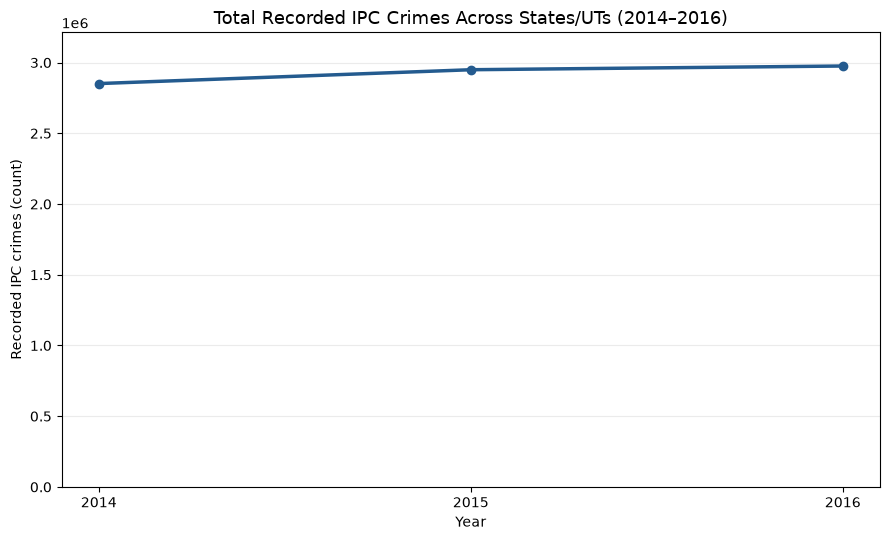

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(yearly_totals.index, yearly_totals.values, marker="o", linewidth=2.5, color="#245b8f")
ax.set(title="Total Recorded IPC Crimes Across States/UTs (2014–2016)",
       xlabel="Year", ylabel="Recorded IPC crimes (count)")
ax.set_xticks([2014, 2015, 2016])
ax.set_ylim(0, yearly_totals.max() * 1.08)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 5. Crime counts versus crime rates

A count answers where the most crimes were recorded; it is affected by regional population size. A population-adjusted rate answers a different question. The source defines its 2016 crime rate per 100,000 population. Neither measure alone explains why regions differ.

In [7]:
top_counts = crime.nlargest(10, "crimes_2016")[["state_ut", "category", "crimes_2016", "crime_rate_2016"]]
highest_rates = crime.nlargest(10, "crime_rate_2016")[["state_ut", "category", "crime_rate_2016", "crimes_2016"]]
lowest_rates = crime.nsmallest(10, "crime_rate_2016")[["state_ut", "category", "crime_rate_2016", "crimes_2016"]]
print("Top 10 2016 crime counts; count and rate remain separate measures:")
display(top_counts.reset_index(drop=True))
print("Highest 10 rates (per 100,000 population):")
display(highest_rates.reset_index(drop=True))
print("Lowest 10 rates (per 100,000 population):")
display(lowest_rates.reset_index(drop=True))

Top 10 2016 crime counts; count and rate remain separate measures:


,state_ut,category,crimes_2016,crime_rate_2016
0,Uttar Pradesh,State,282171,128.7
1,Madhya Pradesh,State,264418,337.9
2,Maharashtra,State,261714,217.1
3,Kerala,State,260097,727.6
4,Delhi,UT,209519,974.9
5,Rajasthan,State,180398,246.2
6,Tamil Nadu,State,179896,258.8
7,West Bengal,State,176569,188.2
8,Bihar,State,164163,157.4
9,Karnataka,State,148402,237.2


Highest 10 rates (per 100,000 population):


,state_ut,category,crime_rate_2016,crimes_2016
0,Delhi,UT,974.9,209519
1,Kerala,State,727.6,260097
2,Madhya Pradesh,State,337.9,264418
3,Haryana,State,320.6,88527
4,Assam,State,313.9,102250
5,Telangana,State,295.7,108991
6,Tamil Nadu,State,258.8,179896
7,Rajasthan,State,246.2,180398
8,Puducherry,UT,242.8,4086
9,Karnataka,State,237.2,148402


Lowest 10 rates (per 100,000 population):


,state_ut,category,crime_rate_2016,crimes_2016
0,Lakshadweep,UT,43.9,36
1,Dadra & Nagar Haveli,UT,57.4,244
2,Nagaland,State,57.6,1376
3,Daman & Diu,UT,81.1,271
4,Uttarakhand,State,101.8,10867
5,Tripura,State,102.4,3933
6,Jharkhand,State,120.4,40710
7,Meghalaya,State,120.9,3366
8,Manipur,State,121.9,3170
9,Sikkim,State,124.7,809


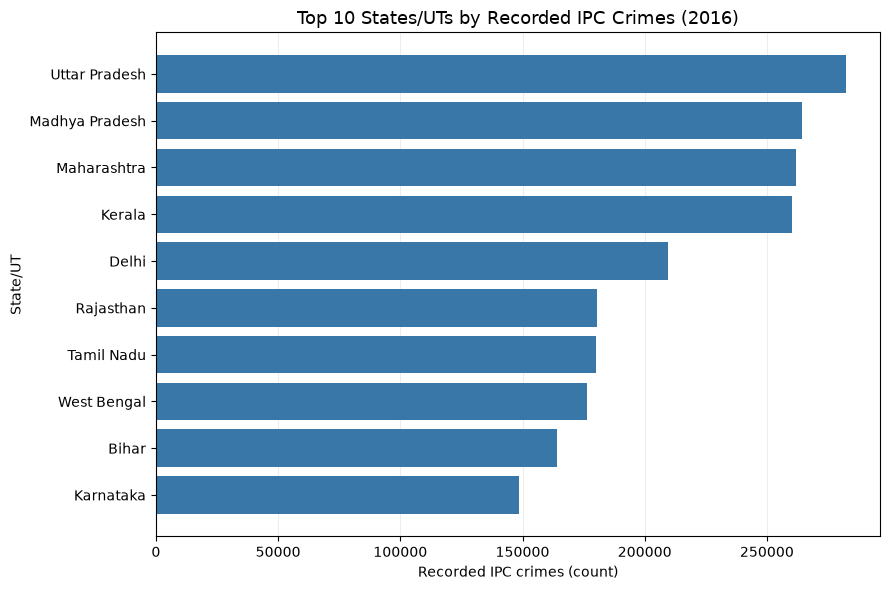

In [8]:
ranked_counts = top_counts.sort_values("crimes_2016")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ranked_counts["state_ut"], ranked_counts["crimes_2016"], color="#3977a8")
ax.set(title="Top 10 States/UTs by Recorded IPC Crimes (2016)",
       xlabel="Recorded IPC crimes (count)", ylabel="State/UT")
ax.grid(axis="x", alpha=0.22)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 6. Regional changes, 2014–2016

Absolute change is `2016 count − 2014 count`. Percentage change is that difference relative to the 2014 count. Absolute change shows the difference in recorded counts; relative change shows its size compared with the baseline. A zero baseline has no defined percentage change and is returned as `NaN` rather than zero.

In [9]:
change = crime["crimes_2016"] - crime["crimes_2014"]
baseline = crime["crimes_2014"].to_numpy(dtype=float)
percentage_change = np.divide(
    change.to_numpy(dtype=float) * 100,
    baseline,
    out=np.full(len(crime), np.nan, dtype=float),
    where=baseline != 0,
)
regional_changes = crime[["state_ut", "category", "crimes_2014", "crimes_2016"]].copy()
regional_changes["absolute_change"] = change
regional_changes["percentage_change"] = percentage_change
largest_increases = regional_changes.nlargest(10, "absolute_change")
largest_decreases = regional_changes.nsmallest(10, "absolute_change")
print("Largest increases:")
display(largest_increases[["state_ut", "category", "absolute_change", "percentage_change"]].reset_index(drop=True).round(2))
print("Largest decreases:")
display(largest_decreases[["state_ut", "category", "absolute_change", "percentage_change"]].reset_index(drop=True).round(2))

Largest increases:


,state_ut,category,absolute_change,percentage_change
0,Delhi,UT,53865,34.61
1,Kerala,State,53308,25.78
2,Uttar Pradesh,State,41696,17.34
3,Gujarat,State,15737,11.98
4,Maharashtra,State,11880,4.76
5,Karnataka,State,11064,8.06
6,Haryana,State,8580,10.73
7,Assam,State,7913,8.39
8,Odisha,State,6891,9.24
9,Punjab,State,2845,7.66


Largest decreases:


,state_ut,category,absolute_change,percentage_change
0,Rajasthan,State,-30020,-14.27
1,Bihar,State,-13432,-7.56
2,Tamil Nadu,State,-13304,-6.89
3,West Bengal,State,-9103,-4.90
4,Madhya Pradesh,State,-8005,-2.94
5,Andhra Pradesh,State,-7830,-6.83
6,Jharkhand,State,-4625,-10.20
7,Chhattisgarh,State,-3171,-5.45
8,Goa,State,-1774,-39.72
9,Tripura,State,-1566,-28.48


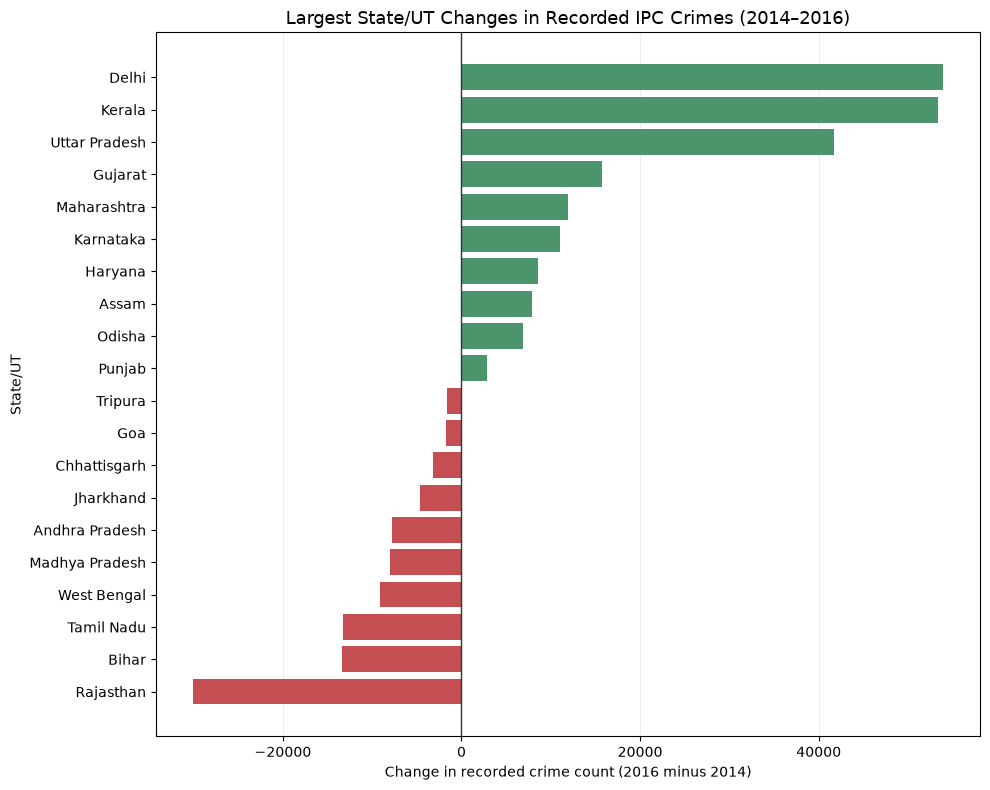

In [10]:
extremes = pd.concat([largest_increases, largest_decreases]).drop_duplicates("state_ut").sort_values("absolute_change")
colors = ["#c44e52" if value < 0 else "#4c956c" for value in extremes["absolute_change"]]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(extremes["state_ut"], extremes["absolute_change"], color=colors)
ax.axvline(0, color="#333333", linewidth=1)
ax.set(title="Largest State/UT Changes in Recorded IPC Crimes (2014–2016)",
       xlabel="Change in recorded crime count (2016 minus 2014)", ylabel="State/UT")
ax.grid(axis="x", alpha=0.22)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 7. States versus Union Territories

The table and box plot compare the **distribution of regional crime rates**, not group crime totals. Each region contributes one value; summaries are not population-weighted. UTs have seven observations compared with 29 States, and the groups also differ in context, so group differences should be interpreted cautiously.

,region_count,mean,median,standard_deviation,minimum,Q1,Q3,IQR,maximum
category,,,,,,,,,
State,29,210.29,192.3,122.41,57.6,128.70,237.2,108.50,727.6
UT,7,244.47,144.8,329.51,43.9,69.25,204.6,135.35,974.9


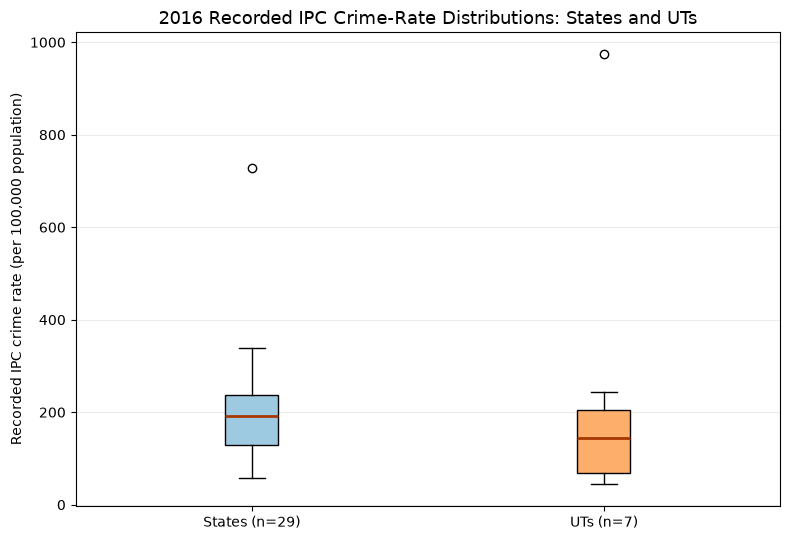

In [11]:
rate_summary = crime.groupby("category")["crime_rate_2016"].agg(
    region_count="count", mean="mean", median="median", standard_deviation="std",
    minimum="min", maximum="max",
)
rate_summary["Q1"] = crime.groupby("category")["crime_rate_2016"].quantile(0.25)
rate_summary["Q3"] = crime.groupby("category")["crime_rate_2016"].quantile(0.75)
rate_summary["IQR"] = rate_summary["Q3"] - rate_summary["Q1"]
display(rate_summary[["region_count", "mean", "median", "standard_deviation", "minimum", "Q1", "Q3", "IQR", "maximum"]].round(2))

state_rates = crime.loc[crime["category"] == "State", "crime_rate_2016"]
ut_rates = crime.loc[crime["category"] == "UT", "crime_rate_2016"]
fig, ax = plt.subplots(figsize=(8, 5.5))
box = ax.boxplot([state_rates, ut_rates],
                 tick_labels=[f"States (n={len(state_rates)})", f"UTs (n={len(ut_rates)})"],
                 patch_artist=True, medianprops={"color": "#a63603", "linewidth": 2})
for patch, color in zip(box["boxes"], ["#9ecae1", "#fdae6b"]):
    patch.set_facecolor(color)
ax.set(title="2016 Recorded IPC Crime-Rate Distributions: States and UTs",
       ylabel="Recorded IPC crime rate (per 100,000 population)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 8. Population and crime rate

Pearson’s *r* measures the strength and direction of a linear association across the regional observations. It does not establish causation. Population size alone does not account for reporting practices, demographic composition, or other factors that can affect recorded rates.

Pearson correlation (n=36 regions): r = 0.075
Interpretation: very weak linear association in this dataset; descriptive, not causal evidence.


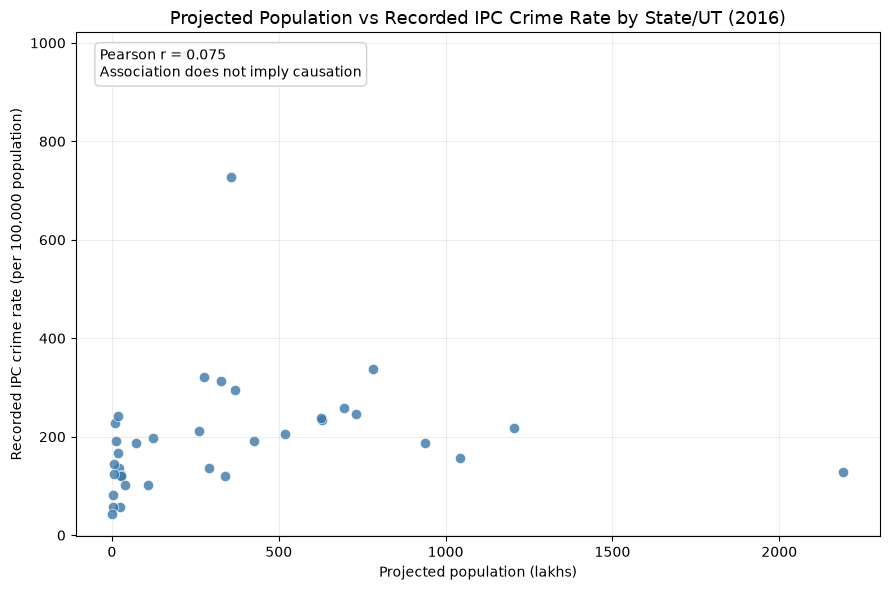

In [12]:
population_rate = crime[["population_lakhs_2016", "crime_rate_2016"]].dropna()
pearson_r = population_rate["population_lakhs_2016"].corr(population_rate["crime_rate_2016"], method="pearson")
print(f"Pearson correlation (n={len(population_rate)} regions): r = {pearson_r:.3f}")
if abs(pearson_r) < 0.1:
    print("Interpretation: very weak linear association in this dataset; descriptive, not causal evidence.")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(population_rate["population_lakhs_2016"], population_rate["crime_rate_2016"],
           s=55, alpha=0.8, color="#3977a8", edgecolor="white", linewidth=0.5)
ax.set(title="Projected Population vs Recorded IPC Crime Rate by State/UT (2016)",
       xlabel="Projected population (lakhs)", ylabel="Recorded IPC crime rate (per 100,000 population)")
ax.text(0.03, 0.97, f"Pearson r = {pearson_r:.3f}\nAssociation does not imply causation",
        transform=ax.transAxes, va="top", ha="left",
        bbox={"boxstyle": "round,pad=.35", "facecolor": "white", "alpha": 0.9, "edgecolor": "#cccccc"})
ax.grid(alpha=0.22)
fig.tight_layout()
plt.show()
assert np.isclose(pearson_r, 0.07513547772808332, atol=1e-12)

## 9. Visual analysis guide

Figures are placed under the analyses they support: a line chart for totals, a horizontal bar chart for count rankings, a diverging chart for positive and negative count changes, a box plot for State/UT rate distributions, and a scatter plot for population and rate. Tables give the rate rankings without repeating the same ranking in another chart. IQR flags are shown with their values and should prompt context—not be treated as errors.

## 10. Findings and conclusion

The summary below reports observations calculated in the preceding cells.

In [13]:
observations = pd.DataFrame({
    "measure": ["2014 total", "2015 total", "2016 total", "2014–2016 absolute change",
                "2014–2016 percentage change", "Highest 2016 count", "Highest 2016 rate",
                "Largest 2014–2016 increase", "Largest 2014–2016 decrease", "Population-rate Pearson r"],
    "result": [
        f"{yearly_totals.loc[2014]:,.0f}", f"{yearly_totals.loc[2015]:,.0f}", f"{yearly_totals.loc[2016]:,.0f}",
        f"{overall_absolute_change:+,}", f"{overall_percentage_change:+.2f}%",
        f"{crime.loc[crime.crimes_2016.idxmax(), 'state_ut']} ({crime.crimes_2016.max():,.0f})",
        f"{crime.loc[crime.crime_rate_2016.idxmax(), 'state_ut']} ({crime.crime_rate_2016.max():.1f} per 100,000)",
        f"{regional_changes.loc[regional_changes.absolute_change.idxmax(), 'state_ut']} (+{regional_changes.absolute_change.max():,.0f}; {regional_changes.loc[regional_changes.absolute_change.idxmax(), 'percentage_change']:+.2f}%)",
        f"{regional_changes.loc[regional_changes.absolute_change.idxmin(), 'state_ut']} ({regional_changes.absolute_change.min():,.0f}; {regional_changes.loc[regional_changes.absolute_change.idxmin(), 'percentage_change']:+.2f}%)",
        f"{pearson_r:.3f}",
    ],
})
display(observations)

,measure,result
0,2014 total,"2,851,563"
1,2015 total,"2,949,400"
2,2016 total,"2,975,711"
3,2014–2016 absolute change,"+124,148"
4,2014–2016 percentage change,+4.35%
5,Highest 2016 count,"Uttar Pradesh (282,171)"
6,Highest 2016 rate,"Delhi (974.9 per 100,000)"
7,Largest 2014–2016 increase,"Delhi (+53,865; +34.61%)"
8,Largest 2014–2016 decrease,"Rajasthan (-30,020; -14.27%)"
9,Population-rate Pearson r,0.075


### Interpretation and limitations

**Observed:** Recorded totals rose from 2014 to 2016, with a smaller percentage increase from 2015 to 2016 than from 2014 to 2015. Uttar Pradesh had the highest 2016 count; Delhi had the highest 2016 rate. These identify different aspects of the data because counts and population-adjusted rates answer different questions. Delhi and Kerala are beyond the overall rate box plot’s upper 1.5-IQR fence; this does not establish that their values are wrong.

**Limitations:** Three annual observations are insufficient to establish a durable trend. Recorded-crime data depend on reporting and classification. State and UT groups have unequal sample sizes and are not population-weighted. The correlation is descriptive and does not explain causes.

**Future questions:** How do patterns compare with later years under comparable definitions? Do regional comparisons change when rates are tracked over time? How do reporting and demographic differences affect these comparisons?